# EDA — SYN DoS packets

**Purpose:** explore the silver table before designing gold and the model. Not a pipeline step (the Job will not run it).

**Reads from:** `kitsune_dev.silver.syn_dos_packets`

**Goals:**
1. Attack timeline: where attacks are and where the clean normal prefix ends
2. HH_jit timestamp hypothesis
3. Features by block: normal vs attack

## 1. Attack timeline

**What:** find the first and last attack packet (by `_row_number`) and count attack rows.

**Why:** the model will train only on normal traffic, so we need to know where the clean normal prefix ends.

**Result:** first/last attack row and number of attack rows.

In [0]:
from pyspark.sql import functions as F

# Same config pattern as 03
CATALOG = "kitsune_dev"
SILVER_PACKETS = f"{CATALOG}.silver.syn_dos_packets"

packets = spark.table(SILVER_PACKETS)

# Keep only attack rows, then get their first/last row number and count
attack_span = (
    packets
    .filter(F.col("label") == 1)
    .agg(
        F.min("_row_number").alias("first_attack"),
        F.max("_row_number").alias("last_attack"),
        F.count("*").alias("attack_rows"),
    )
)

display(attack_span)

# Keep the first attack row to reuse in the charts (no hardcoded numbers)
FIRST_ATTACK = attack_span.first()["first_attack"]
print(f"The first attack occurs on row:", FIRST_ATTACK)

first_attack,last_attack,attack_rows
2682350,2771276,7038


The first attack occurs on row: 2682350


**Findings:**
- First attack at row **2,682,350**, last attack at row **2,771,276** (the last row of the file). **7,038** attack packets in total.
- Rows **1 to 2,682,349** (96.8% of the data) are **100% normal**. This is the clean prefix we will use to train the model on normal traffic only, like the original Kitsune.
- The attack zone has 88,927 rows but only 7,038 attacks, so attacks are **mixed with normal traffic**, not one solid block (`last - first + 1 != attack_rows`).
- We do **not** train on every `label = 0` row: normal packets inside the attack zone come later in time, and their features summarize recent traffic that includes the attack.

### Attack timeline chart

**What:** group packets into bins of 10,000 rows and plot how many attacks fall in each bin.

**Why:** shows at a glance where the attack starts and that the first 96.8% of traffic is clean.

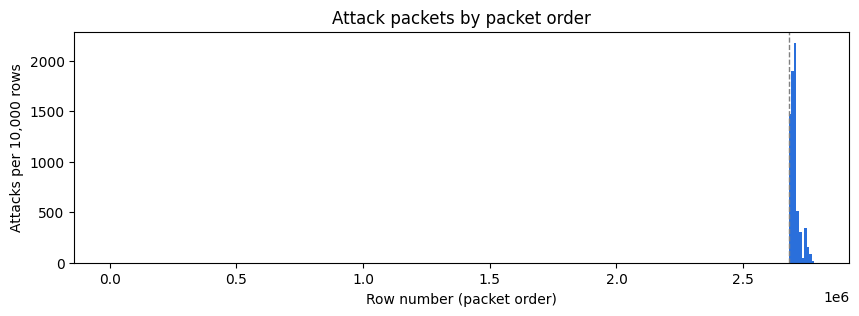

In [0]:
import matplotlib.pyplot as plt

BIN_SIZE = 10_000  # rows per bin

# Put each packet in a bin and count attacks per bin
attacks_per_bin = (
    packets
    .withColumn("bin", F.floor(F.col("_row_number") / BIN_SIZE))
    .groupBy("bin")
    .agg(F.sum("label").alias("attacks"))  # label is 0/1, so the sum = number of attacks
    .orderBy("bin")
    .toPandas()  # safe: only ~278 rows after the groupBy
)

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(attacks_per_bin["bin"] * BIN_SIZE, attacks_per_bin["attacks"],
       width=BIN_SIZE, color="#2a6fdb" , align="edge")
ax.axvline(FIRST_ATTACK, color="gray", linestyle="--", linewidth=1)  # first attack
ax.set_xlabel("Row number (packet order)")
ax.set_ylabel(f"Attacks per {BIN_SIZE:,} rows")
ax.set_title("Attack packets by packet order")
plt.show()

### Zoom: attack zone

**What:** only rows from 2,680,000 onward, bins of 1,000 rows, showing the share of attack packets per bin.

**Why:** the full chart squeezes the attack into the last 3%; zooming in shows how attacks mix with normal traffic.

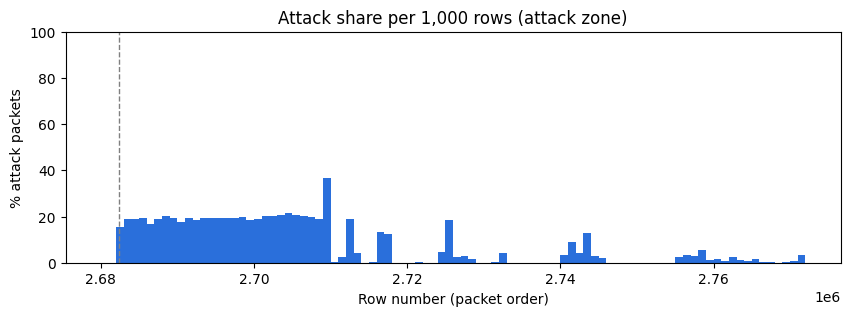

In [0]:
ZOOM_START = 2_680_000
ZOOM_BIN = 1_000  # rows per bin

# Share of attack packets per bin, only inside the attack zone
attack_share = (
    packets
    .filter(F.col("_row_number")>=ZOOM_START)
    .withColumn("bin", F.floor(F.col("_row_number") / ZOOM_BIN))
    .groupBy("bin")
    .agg(F.avg("label").alias("attack_share"))  # avg of 0/1 = share of attacks
    .orderBy("bin")
    .toPandas()  # ~92 rows
)

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(attack_share["bin"] * ZOOM_BIN, attack_share["attack_share"] * 100,
       width=ZOOM_BIN, color="#2a6fdb", align="edge")
ax.axvline(FIRST_ATTACK, color="gray", linestyle="--", linewidth=1)  # first attack
ax.set_ylim(0, 100)  # fixed 0-100% scale so the share is not exaggerated
ax.set_xlabel("Row number (packet order)")
ax.set_ylabel("% attack packets")
ax.set_title(f"Attack share per {ZOOM_BIN:,} rows (attack zone)")
plt.show()

**Findings:**
- The attack never takes over the traffic: the highest bin is **~37%** attack packets. Normal traffic keeps flowing during the attack.
- **Two phases:** a sustained flood (rows ~ 2,682k – 2,710k) at a steady **~20%** attack share, then **short bursts** separated by bins with 0% attacks.
- Confirms training on the clean prefix only: normal bins inside the attack zone sit right next to attack bursts.
- For evaluation: the low-share bursts (2–5%) will be harder to detect than the sustained flood, so we should look at how the model does on each phase, not only the overall score.

- Caveat: the x-axis is packet order, not time. Bins hold 1,000 packets each but cover different time spans, so these charts show the *share* of attack packets, not attack intensity over time.

## 2. HH_jit timestamp hypothesis

**What:** count rows where `hh_jit_l0_01_mean` (average time gap between packets) is larger than 1e9 seconds (~31 years).

**Why:** a real time gap can't be 31 years. If such values exist, they are probably full Unix timestamps leaked by the feature extractor, not real gaps.

**Result:** min, max and number of "impossible" values.

In [0]:
TIMESTAMP_THRESHOLD = 1e9  # 1e9 seconds = ~31 years: no real gap is this big
col = F.col("hh_jit_l0_01_mean")

jit_check = packets.agg(
    F.min(col).alias("min_value"),
    F.max(col).alias("max_value"),
    F.count_if(col >= TIMESTAMP_THRESHOLD).alias("rows_above_threshold"),
    F.from_unixtime(F.max(col)).alias("max_as_date"),  # seconds since 1970 -> readable date
)

display(jit_check)

min_value,max_value,rows_above_threshold,max_as_date
0.003098576929746486,1.488014482046588E9,537,2017-02-25 09:21:22


**Findings:**
- **537** rows have `hh_jit_l0_01_mean` above 1e9 seconds (~31 years), which is impossible for a real time gap.
- The max value, **1,488,014,482**, converts to **2017-02-25 09:21 UTC**, a real date from when the dataset was recorded. This supports the hypothesis: these are full Unix timestamps, not gaps.
- The min value (~3 ms) is a normal gap, so the column **mixes two kinds of values** about 500 billion times apart.
- Open question: this column is a running average, so a leaked timestamp may also inflate the following rows below the 1e9 threshold. To check next.


### All 5 HH_jit mean columns

**What:** count values above 1e9 in each HH_jit mean column (one per time window λ), in a single pass.

**Why:** if the timestamp leak is real, it should show up in every window, not just λ = 0.01.

In [0]:
from src.kitsune.feature_names import feature_names

# The 5 HH_jit mean columns (one per time window)
jit_mean_cols = []
for c in feature_names():
    if c.startswith("hh_jit") and c.endswith("_mean"):
        jit_mean_cols.append(c)

print(jit_mean_cols)

# One count per column, all computed in a single pass over the data
count_exprs = []
for c in jit_mean_cols:
    count_exprs.append(F.count_if(F.col(c) >= TIMESTAMP_THRESHOLD).alias(c))

jit_counts = packets.agg(*count_exprs)
display(jit_counts)

['hh_jit_l5_mean', 'hh_jit_l3_mean', 'hh_jit_l1_mean', 'hh_jit_l0_1_mean', 'hh_jit_l0_01_mean']


hh_jit_l5_mean,hh_jit_l3_mean,hh_jit_l1_mean,hh_jit_l0_1_mean,hh_jit_l0_01_mean
537,537,537,537,537



**Findings:**
- All 5 HH_jit mean columns have exactly **537** values above 1e9, one count per time window.
- Same count in every window → these are most likely the **first packet of 537 new conversations**: with only one sample, the mean equals that sample (the leaked timestamp) no matter how fast the window forgets.
- Open question: from the second packet on, the mean drops below 1e9 but can still be absurd (e.g. hundreds of millions of seconds). The 1e9 threshold only catches the first packet.

### Contaminated rows after the first packet

**What:** count values above 11 days (in seconds) in each HH_jit mean column.

**Why:** the 1e9 threshold only catches the first packet of each conversation. The mean is a running average, so the leaked timestamp keeps inflating the next packets below 1e9. 11 days is still an impossible gap between two packets of the same conversation.

In [0]:
CONTAMINATION_THRESHOLD = 11 * 24 * 60 * 60  # ~11 days in seconds

# jit_mean_cols already exists from 2b, reuse it
count_exprs = []
for c in jit_mean_cols:
    count_exprs.append(F.count_if(F.col(c) >= CONTAMINATION_THRESHOLD).alias(c))

contaminated_counts = packets.agg(*count_exprs)
display(contaminated_counts)

hh_jit_l5_mean,hh_jit_l3_mean,hh_jit_l1_mean,hh_jit_l0_1_mean,hh_jit_l0_01_mean
1577,2170,3984,7990,10427


**Findings:**
- Every window has more than 537 contaminated rows: the leak spreads past the first packet.
- The count grows as λ gets smaller: **1,577** (λ=5) → 2,170 → 3,984 → 7,990 → **10,427** (λ=0.01). Small λ means slow forgetting, so the leaked timestamp stays in the mean for more packets (~3 per conversation at λ=5 vs ~19 at λ=0.01).
- Only ~0.38% of rows, but the values are extreme (up to 1.5e9). One value like that is enough to break min-max scaling for the whole column, so this must be handled in gold.

### Leaked timestamps as a clock

**What:** list the 537 rows where `hh_jit_l0_01_mean` is above 1e9, with their row number and the value converted to a date.

**Why:** if these dates increase with `_row_number`, the leaked timestamps work as a real time axis for the capture (our charts so far use packet order, not time).

In [0]:
# Rows where the mean is a leaked timestamp (first packet of a new conversation)
leaked = (
    packets
    .filter(col >= TIMESTAMP_THRESHOLD)  # keep only rows above 1e9
    .select(
        "_row_number",
        F.col("hh_jit_l0_01_mean").alias("leaked_ts"),
        F.from_unixtime("hh_jit_l0_01_mean").alias("leaked_date"),  # seconds -> readable date
    )
    .orderBy("_row_number")
)

display(leaked)

_row_number,leaked_ts,leaked_date
1,1.488011312825815E9,2017-02-25 08:28:32
80,1.488011312834693E9,2017-02-25 08:28:32
115,1.48801131285973E9,2017-02-25 08:28:32
149,1.488011312871084E9,2017-02-25 08:28:32
294,1.488011312998803E9,2017-02-25 08:28:32
1952,1.488011314872735E9,2017-02-25 08:28:34
2980,1.488011315997336E9,2017-02-25 08:28:35
3084,1.488011316099863E9,2017-02-25 08:28:36
3133,1.488011316197499E9,2017-02-25 08:28:36
3245,1.488011316297368E9,2017-02-25 08:28:36


**Check:** count how many leaked timestamps are smaller than the previous one (by `_row_number`). If the count is 0, the timestamps always increase with packet order.

In [0]:
from pyspark.sql import Window

by_row = Window.orderBy("_row_number")  # defines what "previous row" means

decreases = (
    leaked
    .withColumn("prev_ts", F.lag("leaked_ts").over(by_row))  # value from the previous row
    .agg(F.count_if(F.col("leaked_ts") < F.col("prev_ts")).alias("decreasing_steps"))
)

display(decreases)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


decreasing_steps
0


**Findings:**
- `decreasing_steps = 0`: the leaked timestamps **always increase** with `_row_number`. They are real packet arrival times, and the file is stored in **arrival order**. This supports the chronological train/test split planned for gold.
- The capture runs from **08:28:32** (row 1) to **09:21:22** (last row) on 2017-02-25: about **53 minutes** of traffic.
- The clocks are unevenly spread: there is no leaked timestamp between row 1,005,961 (08:47:22) and row 2,700,046 (09:19:41), a 32-minute blind gap. So we can't pin the exact time the attack started, only that it was before 09:19:41.
- Open question: most leaked rows seem to sit inside the attack zone, often in consecutive rows. If new conversations are a signature of the attack, the leak could let a model detect attacks through the bug instead of real traffic behavior. To check next.

### Leaked timestamps by zone

**What:** count leaked timestamps before and after the first attack, and how many of them are attack packets.

**Why:** if the leak shows up mostly in attack packets, a model could learn to detect attacks through the bug instead of real traffic behavior (a shortcut).

In [0]:
leaked_by_zone = (
    packets
    .filter(col >= TIMESTAMP_THRESHOLD)  # only leaked rows
    .withColumn(
        "zone",
        F.when(F.col("_row_number") >= FIRST_ATTACK, "attack_zone").otherwise("normal_prefix"),
    )
    .groupBy("zone")
    .agg(
        F.count("*").alias("leaked_rows"),
        F.sum("label").alias("attack_rows"),  # label is 0/1, so the sum = attacks
    )
)

display(leaked_by_zone)

zone,leaked_rows,attack_rows
attack_zone,492,490
normal_prefix,45,0



**Findings:**
- **537** leaked timestamps: **45** in the normal prefix (none are attacks) and **492** in the attack zone, of which **490 are attack packets** (99.6%).
- The leak marks packets that open a new conversation. In a SYN flood most attack packets look like new conversations (likely spoofed source IPs), so the bug is concentrated in attack traffic.
- **Shortcut risk:** a value of ~1.4e9 in the HH_jit columns almost guarantees an attack. A model could learn this bug instead of real traffic behavior, inflating the metrics and failing on real networks where the bug doesn't exist. These columns must be treated in gold before training.

### All HH_jit statistics

**What:** list the 15 HH_jit columns (3 statistics × 5 windows) and get the max of each one.

**Why:** so far we only checked the `mean` columns. Before deciding what to remove in gold, check if `weight` and `variance` also carry the leaked timestamp.

In [0]:
# All HH_jit columns (every statistic, every window)
jit_cols = []
for c in feature_names():
    if c.startswith("hh_jit"):
        jit_cols.append(c)

print(len(jit_cols))
for c in jit_cols:
    print(c)

15
hh_jit_l5_weight
hh_jit_l5_mean
hh_jit_l5_variance
hh_jit_l3_weight
hh_jit_l3_mean
hh_jit_l3_variance
hh_jit_l1_weight
hh_jit_l1_mean
hh_jit_l1_variance
hh_jit_l0_1_weight
hh_jit_l0_1_mean
hh_jit_l0_1_variance
hh_jit_l0_01_weight
hh_jit_l0_01_mean
hh_jit_l0_01_variance


In [0]:
# Max of every HH_jit column, in a single pass
max_exprs = []
for c in jit_cols:
    max_exprs.append(F.max(c).alias(c))

jit_max = packets.agg(*max_exprs)
display(jit_max)

hh_jit_l5_weight,hh_jit_l5_mean,hh_jit_l5_variance,hh_jit_l3_weight,hh_jit_l3_mean,hh_jit_l3_variance,hh_jit_l1_weight,hh_jit_l1_mean,hh_jit_l1_variance,hh_jit_l0_1_weight,hh_jit_l0_1_mean,hh_jit_l0_1_variance,hh_jit_l0_01_weight,hh_jit_l0_01_mean,hh_jit_l0_01_variance
210.47121077466855,1.488014482046588E9,5.53544440001918E17,291.7599250670151,1.488014482046588E9,5.5354444298214637E17,721.5047962302045,1.488014482046588E9,5.535444830602209E17,5609.796711263494,1.488014482046588E9,5.5354524208779264E17,46746.29813094739,1.488014482046588E9,5.535452568276387E17


**Findings:**
- **weight** is clean (max between ~210 and ~46,700): it only counts packets, so a wrong timestamp doesn't inflate it.
- **mean** has the leak in all 5 windows (max = 1,488,014,482).
- **variance** also has it in all 5 windows (max ≈ 5.5e17). Variance is in seconds squared, so the leaked value gets squared: (1,488,014,482 / 2)² ≈ 5.5e17.
- **Decision for gold:** drop the 10 HH_jit `mean` and `variance` columns, keep the 5 `weight` columns. Silver keeps all 115 columns, so we can later compare a model trained with and without them.

## 3. Features by block: normal vs attack

**What:** for each block of columns, compare the average of every column in normal vs attack packets.

**Why:** a column that is very different between normal and attack can be a real attack signal (good) or a hidden artifact like the HH_jit leak (bad). We want to know which is which before building gold.

In [0]:
def avg_by_label(prefix):
    """Average of every column that starts with `prefix`, one row per label."""
    cols = []
    for c in feature_names():
        if c.startswith(prefix):
            cols.append(c)

    avg_exprs = []
    for c in cols:
        avg_exprs.append(F.avg(c).alias(c))

    return packets.groupBy("label").agg(*avg_exprs).orderBy("label")

In [0]:
display(avg_by_label("mi"))

label,mi_l5_weight,mi_l5_mean,mi_l5_variance,mi_l3_weight,mi_l3_mean,mi_l3_variance,mi_l1_weight,mi_l1_mean,mi_l1_variance,mi_l0_1_weight,mi_l0_1_mean,mi_l0_1_variance,mi_l0_01_weight,mi_l0_01_mean,mi_l0_01_variance
0,62.13701238779318,801.7611419550219,306051.5042306365,99.67371026538667,802.47908045811,306176.1003171292,291.466962239334,803.4084192709032,306245.6636680664,2882.4334858518723,803.8970482373973,306270.86921127915,27428.15648388797,804.2491386587436,306439.37067356677
1,55.225545126800895,1089.8676125203308,45272.208730062855,85.2766702844941,1094.6470827446142,48434.20876723518,234.12464683738364,1115.0528848033541,58312.56643366988,2351.523519401915,1260.1304945459206,107751.73335302276,26001.030062710157,1390.1991500151594,59243.180178054965


**Findings (MI block):**
- Attack packets come from senders with **larger** and much more **uniform** packet sizes: mean \~1,090–1,390 bytes vs \~802 for normal, and variance roughly 3–7 times lower.
- `weight` is similar in both groups.
- This looks like a **real attack signal, not an artifact**: the values are physically possible (below the \~1,514-byte max Ethernet frame), the difference is moderate (\~1.4×), and it changes smoothly across windows. Compare with HH_jit, where values were impossible (decades between packets).
- Note: MI summarizes the sender's recent traffic, not a single packet, so the mean is not the size of one SYN. The dataset has no IP/MAC addresses, so we can't explain the exact reason.

### H block (source host)

**What:** same comparison for the H block: packets from the same source IP, packet size statistics (15 columns).

**Why:** check if this block also carries a real attack signal or an artifact.

In [0]:
h_avg = avg_by_label("h_")
print(f"Number of feature columns:", len(h_avg.columns) - 1)  # number of columns minus the label column
display(h_avg)

Number of feature columns: 15


label,h_l5_weight,h_l5_mean,h_l5_variance,h_l3_weight,h_l3_mean,h_l3_variance,h_l1_weight,h_l1_mean,h_l1_variance,h_l0_1_weight,h_l0_1_mean,h_l0_1_variance,h_l0_01_weight,h_l0_01_mean,h_l0_01_variance
0,62.13701414877525,801.7611348119516,306051.5053947405,99.67371310830693,802.4790745401318,306176.1023249787,291.4669716316807,803.40839957934,306245.67014200607,2882.4335809504255,803.8970342987951,306270.8933885203,27428.15739887969,804.2490928909192,306439.40998328466
1,55.225545126800895,1089.8676125203308,45272.208730062855,85.2766702844941,1094.6470827446142,48434.20876723518,234.12464683738364,1115.0528848033541,58312.56643366988,2351.523519401915,1260.1304945459206,107751.73335302276,26001.030062710157,1390.1991500151594,59243.180178054965


**Findings (H block):**
- H is almost identical to MI: same values for attack packets, and normal packets differ only around the 7th digit. Each device uses (almost) always the same IP, so grouping by MAC+IP (MI) or by IP (H) gives nearly the same groups.
- Same real attack signal as MI (larger, more uniform packet sizes), no artifact.
- **Redundancy, not a shortcut:** H adds almost no information over MI. To consider in gold (duplicated features give that signal double weight).
- Pitfall found: `startswith("h")` matched 100 columns (H, HH, HH_jit and HpHp). The prefix must be `"h_"`. Checking the column count caught it.

### HH block (host to host)

**What:** same comparison for the HH block: packets between the same two IPs (A ↔ B), 7 statistics × 5 windows = 35 columns.

**Why:** check for a real attack signal or an artifact. The HH_jit leak came from this same host-to-host grouping, so this block deserves a close look.

In [0]:
hh_avg = avg_by_label("hh_l")
print(f"Number of feature columns:", len(hh_avg.columns) - 1)
display(hh_avg)

Number of feature columns: 35


label,hh_l5_weight,hh_l5_mean,hh_l5_variance,hh_l5_radius,hh_l5_magnitude,hh_l5_cov,hh_l5_pcc,hh_l3_weight,hh_l3_mean,hh_l3_variance,hh_l3_radius,hh_l3_magnitude,hh_l3_cov,hh_l3_pcc,hh_l1_weight,hh_l1_mean,hh_l1_variance,hh_l1_radius,hh_l1_magnitude,hh_l1_cov,hh_l1_pcc,hh_l0_1_weight,hh_l0_1_mean,hh_l0_1_variance,hh_l0_1_radius,hh_l0_1_magnitude,hh_l0_1_cov,hh_l0_1_pcc,hh_l0_01_weight,hh_l0_01_mean,hh_l0_01_variance,hh_l0_01_radius,hh_l0_01_magnitude,hh_l0_01_cov,hh_l0_01_pcc
0,62.10757812312258,801.755434981589,498.45998747121547,923.6722802398978,309520.58271430555,-1.0324529850283204,-3.32233392320007E-5,99.62463692308927,802.4753356626135,499.429084895611,924.8695187510507,309724.6231952501,-1.2082368701347308,-3.71479693535749E-5,291.3200931766494,803.4066245075871,500.2160028313139,926.2740608816096,309958.4367607023,-1.1393424518391548,-3.2093347533621157E-5,2880.9668181452525,803.8946862726402,500.51944010817493,926.9628013743328,310078.8395237838,-1.8429150343973941,-4.624997408616133E-5,27414.050976275445,804.237752568908,500.7181094541048,927.3309964598108,310237.3312982635,1.7452171711945208,1.0097620157735498E-4
1,43.331944520055565,1075.0222252727742,152.1145113363367,1075.9893350504985,32559.706843389744,0.009839308788795688,2.4342122320928355E-5,69.63605235724289,1074.2912853821215,156.15094514543944,1075.2589557944316,33304.30623103866,0.013523802579744948,3.315455325045322E-5,203.87622270699356,1073.6143479022687,159.18646249708308,1074.5824673566137,33843.95594347813,0.029568877944459657,3.088032709441367E-5,2030.7491569132662,1072.5428208692063,161.23946341326732,1073.511717462152,34451.75418430757,0.0015833810101902228,7.843047231688114E-6,20298.050454950328,1072.7116208258765,159.79073277838296,1073.6803600491535,33829.47482106905,1.6069307374837975E-4,2.6638303739893453E-6


**Findings (HH block):**
- Prefix pitfall #2: `"hh_"` also matched the 15 HH_jit columns (50 instead of 35). The prefix must be `"hh_l"`.
- Same real attack signal as MI and H: attack packets are larger (mean \~1,074 vs \~803 bytes), and in HH the attack mean stays almost the same across all 5 windows.
- No artifact: values are physically possible, correlations (`pcc`) stay between -1 and 1, and differences are moderate. Compare with HH_jit, where the attack mean was \~103 million.
- Limitation: averages can hide a few extreme values. We only checked the max for HH_jit.